# Human Study: Do the Highlights Help People?

`xai_evaluation.ipynb` checks the SVM's LIME explanations with code. This notebook checks whether they actually help **people**.

**The task.** Participants fill in a Google Form (built from the highlighted pages `form_A.html` and `form_B.html`). They read a news article and guess what the **model** will say: fake or real.

**The design.**
- Ten test articles, chosen to include the model's mistakes: 3 fakes it caught, 2 real articles it wrongly flagged, 3 real articles it passed, and 2 fakes it missed.
- Each person sees all ten. For five of them, the words LIME says the model relied on are highlighted (red = pushes toward fake, blue = pushes toward real).
- There are two versions of the Google Form. **Form A** highlights items 1-5 and **Form B** highlights items 6-10, so every article is seen with and without highlights, by different people.
- Two practice articles with the model's answer come first.

The model is the RBF SVM, the black box tested in `xai_evaluation.ipynb`. Logistic regression, our recommended model, doesn't need LIME, because its coefficients show its reasons exactly.

In [1]:
import os, sys, time, html
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import joblib
from IPython.display import display
from sklearn.svm import SVC
from lime.lime_text import LimeTextExplainer

from preprocessing import preprocess_text, get_split_tfidf, RANDOM_STATE

STUDY_DIR = "Model/Human Study/human_eval"
SVM_CACHE = "Model/XAI Evaluation/svm_rbf.joblib"     # same saved SVM as xai_evaluation.ipynb

## 1. Data and Model

Same data, preprocessing, split and SVM as the model notebooks. If `xai_evaluation.ipynb` has already been run, the saved SVM is loaded; otherwise it is trained here (several minutes) and saved.

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)

X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
test_raw = df.loc[y_test.index, "full_text"].reset_index(drop=True)
test_title = df.loc[y_test.index, "title"].reset_index(drop=True)
test_body = df.loc[y_test.index, "text"].reset_index(drop=True)
y_true = y_test.to_numpy()

# test articles whose start also appears in training (skipped, so nobody sees a near-copy)
train_heads = set(df.loc[y_train.index, "processed_text"].str[:300])
near_dup = test_text.str[:300].isin(train_heads).to_numpy()

In [3]:
os.makedirs(os.path.dirname(SVM_CACHE), exist_ok=True)
if os.path.exists(SVM_CACHE):
    svm_model = joblib.load(SVM_CACHE)
    print("Loaded saved SVM from", SVM_CACHE)
else:
    t0 = time.time()
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE).fit(X_train, y_train)
    joblib.dump(svm_model, SVM_CACHE)
    print(f"Trained SVM in {time.time() - t0:.0f} s and saved it")

svm_score = svm_model.decision_function(X_test)     # > 0 means fake
svm_pred = (svm_score > 0).astype(int)

def svm_proba_text(texts):
    # LIME needs scores between 0 and 1: same sigmoid of the SVM score as in SVM.ipynb
    p = 1 / (1 + np.exp(-svm_model.decision_function(tfidf.transform(texts))))
    return np.column_stack([1 - p, p])

Loaded saved SVM from Model/XAI Evaluation/svm_rbf.joblib


## 2. Choosing the Ten Articles

Articles are 120 to 350 words long, so they can be read in a minute or two. The table is the answer key: **don't show it to participants.**

In [4]:
rng = np.random.RandomState(RANDOM_STATE + 5)
n_words = test_raw.str.split().str.len()
readable = n_words.between(120, 350).to_numpy() & ~near_dup
pools = {"TP": (y_true == 1) & (svm_pred == 1), "FP": (y_true == 0) & (svm_pred == 1),
         "TN": (y_true == 0) & (svm_pred == 0), "FN": (y_true == 1) & (svm_pred == 0)}
plan = [("TP", 3), ("FP", 2), ("TN", 3), ("FN", 2)]

items = []
for outcome, n in plan:
    cand = np.where(pools[outcome] & readable)[0]
    if len(cand) < n:                                   # too few short ones: allow any length
        cand = np.where(pools[outcome] & ~near_dup)[0]
    items += [(outcome, int(i)) for i in rng.choice(cand, n, replace=False)]
items = [items[k] for k in rng.permutation(len(items))]      # mix the outcomes
practice = [int(rng.choice(np.where(readable & (svm_pred == y_true) & (svm_pred == c))[0])) for c in (1, 0)]

key = pd.DataFrame([{"item": k, "outcome": o, "model_output": "fake" if svm_pred[i] else "real",
                     "true_label": "fake" if y_true[i] else "real",
                     "svm_decision_value": round(float(svm_score[i]), 3),
                     "highlighted_in_form": "A" if k <= 5 else "B", "title": test_title.iloc[i]}
                    for k, (o, i) in enumerate(items, 1)])
display(key)

,item,outcome,model_output,true_label,svm_decision_value,highlighted_in_form,title
0,1,FP,fake,real,0.258,A,"As West frowns on Putin, young Russians learn ..."
1,2,FP,fake,real,0.150,A,Obamas donated less to charities in 2015 as in...
2,3,TN,real,real,-0.888,A,Philippines' Duterte's son quits as vice mayor...
3,4,TN,real,real,-1.330,A,Russian security service says dismantles Islam...
4,5,TP,fake,fake,0.257,A,BREAKING: Ecuadorian Embassy Admits They Cut W...
5,6,TP,fake,fake,1.907,B,WATCH: THE VIEW’s LIBERAL HAGS Attack Meghan M...
6,7,FN,real,fake,-0.135,B,BREAKING: Iran Publicly Humiliates Obama…Unvei...
7,8,TP,fake,fake,0.819,B,Mitch McConnell: The Republican Platform Won’t...
8,9,FN,real,fake,-0.115,B,UNREAL! FORMER GITMO DETAINEES PROTEST AT U.S....
9,10,TN,real,real,-2.156,B,Congress watchdog to investigate Trump voter f...


## 3. Making the Forms

For each article, LIME (2,000 samples) finds the six words the SVM relied on most, and those words are highlighted in the text. This writes `form_A.html`, `form_B.html`, `answer_key.csv` and an empty `response_template.csv` to `Model/Human Study/human_eval/`.

In [5]:
explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def highlight(i):
    exp = explainer.explain_instance(test_text.iloc[i], svm_proba_text, num_features=6, num_samples=2000, labels=(1,))
    weights = dict(exp.as_list(label=1))
    def mark(raw):
        out = []
        for tok in raw.split():
            lemma = preprocess_text(tok).strip()
            if lemma in weights:
                color = "#f4a6a6" if weights[lemma] > 0 else "#a6c8f4"
                out.append(f'<span style="background:{color}">{html.escape(tok)}</span>')
            else:
                out.append(html.escape(tok))
        return " ".join(out)
    legend = ", ".join(f"<b>{w}</b> ({'fake' if v > 0 else 'real'})"
                       for w, v in sorted(weights.items(), key=lambda t: -abs(t[1])))
    return mark(test_title.iloc[i]), mark(test_body.iloc[i]), legend

def page(form):
    parts = [f"<html><head><meta charset='utf-8'><title>Study form {form}</title></head>"
             "<body style='font-family:sans-serif;max-width:820px;margin:auto'>",
             f"<h2>Fake-news screening study: Form {form}</h2>",
             "<p>A computer model labels each article as <b>FAKE</b> or <b>REAL</b>. "
             "Your task is <b>not</b> to judge whether the article is true. Guess what the <b>model</b> will say. "
             "For some articles you will see the words the model relied on: "
             "<span style='background:#f4a6a6'>red pushes toward FAKE</span>, "
             "<span style='background:#a6c8f4'>blue pushes toward REAL</span>.</p>"
             "<h3>Practice (answers shown)</h3>"]
    for k, i in enumerate(practice, 1):
        parts.append(f"<h4>Practice {k}: {html.escape(test_title.iloc[i])}</h4>"
                     f"<p>{html.escape(' '.join(test_body.iloc[i].split()[:150]))} ...</p>"
                     f"<p><i>The model said: {'FAKE' if svm_pred[i] else 'REAL'}</i></p>")
    parts.append("<h3>Test items</h3>")
    for k, (_, i) in enumerate(items, 1):
        show = (k <= 5) if form == "A" else (k > 5)
        if show:
            title, body, legend = highlights[i]
            parts.append(f"<h4>Item {k}: {title}</h4><p>{body}</p><p>Words the model relied on: {legend}</p>")
        else:
            parts.append(f"<h4>Item {k}: {html.escape(test_title.iloc[i])}</h4><p>{html.escape(test_body.iloc[i])}</p>")
        parts.append("<p>What will the model say? &#9744; FAKE &#9744; REAL &nbsp;&nbsp; "
                     "Confidence (1-5): ____ &nbsp;&nbsp; Comment: ________________</p><hr>")
    parts.append("</body></html>")
    return "\n".join(parts)

t0 = time.time()
highlights = {i: highlight(i) for _, i in items}      # one LIME run per article, shared by both forms
os.makedirs(STUDY_DIR, exist_ok=True)
for form in ("A", "B"):
    with open(f"{STUDY_DIR}/form_{form}.html", "w", encoding="utf-8") as fh:
        fh.write(page(form))
key.to_csv(f"{STUDY_DIR}/answer_key.csv", index=False)
pd.DataFrame(columns=["participant_id", "form", "background", "item", "predicted_model_output",
                      "confidence_1to5", "seconds", "comment"]).to_csv(f"{STUDY_DIR}/response_template.csv", index=False)
print(f"Forms written to {STUDY_DIR} in {time.time() - t0:.0f} s")

Forms written to Model/Human Study/human_eval in 59 s


## 4. Participants

Ten people took part (5 completed `form_A.html` and 5 completed `form_B.html`). Each person saw the same 10 test articles, but the two forms highlight different articles: five articles show LIME's top six words and five are plain, so every article was seen with highlights by 5 participants and without them by the other 5. For each article, participants predicted what the SVM would output (fake or real) and rated their confidence from 1 to 5. They were told to predict the model's output, not whether the article is true. Before the 10 test articles, participants saw two practice articles with the model's answer shown. These are not counted in the 100 responses. Answers were collected in `responses.csv`, which follows the layout of `response_template.csv` and holds 100 responses in total (10 participants × 10 articles).

Participants were friends and classmates, recruited through direct messages. No personal data was collected beyond a participant ID.

## 5. Results

We score each answer as correct if it matches what the SVM actually output, then compare the highlighted and plain conditions. The cells below show overall accuracy, accuracy split by whether the SVM itself was wrong, average confidence, and the participants' comments, followed by Table and a bar chart.

In [6]:
resp_path = f"{STUDY_DIR}/responses.csv"
if os.path.exists(resp_path):
    resp = pd.read_csv(resp_path, index_col=False).merge(key[["item", "model_output", "outcome", "highlighted_in_form"]], on="item")
    resp["condition"] = np.where(resp["form"] == resp["highlighted_in_form"], "with highlights", "without highlights")
    resp["correct"] = resp["predicted_model_output"].str.lower().str.strip() == resp["model_output"]
    resp["model_was_wrong"] = resp["outcome"].isin(["FP", "FN"])

    print(f"Participants: {resp.participant_id.nunique()} | answers: {len(resp)}\n")
    print("Correct guesses of the model:")
    display(resp.groupby("condition")["correct"].agg(["mean", "count"]).round(3))
    print("Split by whether the model itself was wrong:")
    display(resp.groupby(["model_was_wrong", "condition"])["correct"].agg(["mean", "count"]).round(3))
    print("Average confidence:")
    display(resp.groupby("condition")["confidence_1to5"].mean().round(2))

    comments = resp.dropna(subset=["comment"])
    comments = comments[comments["comment"].astype(str).str.strip() != ""]
    print("\nComments:")
    for _, r in comments.iterrows():
        print(f"  P{r.participant_id}, item {r['item']} ({r.condition}): {r.comment}")
else:
    print("No responses yet: fill in", resp_path)

Participants: 10 | answers: 100

Correct guesses of the model:


,mean,count
condition,,
with highlights,0.68,50
without highlights,0.52,50


Split by whether the model itself was wrong:


mean  count
model_was_wrong condition                       
False           with highlights     0.900     30
                without highlights  0.633     30
True            with highlights     0.350     20
                without highlights  0.350     20

Average confidence:


condition
with highlights       3.72
without highlights    3.76
Name: confidence_1to5, dtype: float64


Comments:
  P2, item 1 (with highlights): The article is focused on geopolitics so there's a lot of "real" keywords so I think the model will label this as true
  P2, item 2 (with highlights): There are many political figures names which according to the words the model relies on pushes it to be fake 
  P2, item 3 (with highlights): The article mentions many times where statements and events that happen can be found even if they're vague social media Twitter etc
  P2, item 4 (with highlights): Every statement had a "source" so it would likely be flagged as true
  P2, item 5 (with highlights): Many statements but less "sources"
  P3, item 1 (with highlights): more words that pushed towards real than fake
  P3, item 2 (with highlights): More words that push towards it being fake although the use of numbers may make the model say otherwise
  P5, item 1 (with highlights): The way its written


In [7]:
def fmt(df, cond):
    sub = df[df["condition"] == cond]
    k, n = int(sub["correct"].sum()), len(sub)
    return f"{k} / {n} ({k / n:.0%})"

groups = [
    ("All trials", resp),
    ("Model right (TP, TN)", resp[~resp["model_was_wrong"]]),
    ("Model wrong (FP, FN)", resp[resp["model_was_wrong"]]),
]

table3 = pd.DataFrame(
    [[label, fmt(d, "without highlights"), fmt(d, "with highlights")] for label, d in groups],
    columns=["Trials", "Without highlights", "With LIME highlights"],
)

display(table3)

,Trials,Without highlights,With LIME highlights
0,All trials,26 / 50 (52%),34 / 50 (68%)
1,"Model right (TP, TN)",19 / 30 (63%),27 / 30 (90%)
2,"Model wrong (FP, FN)",7 / 20 (35%),7 / 20 (35%)


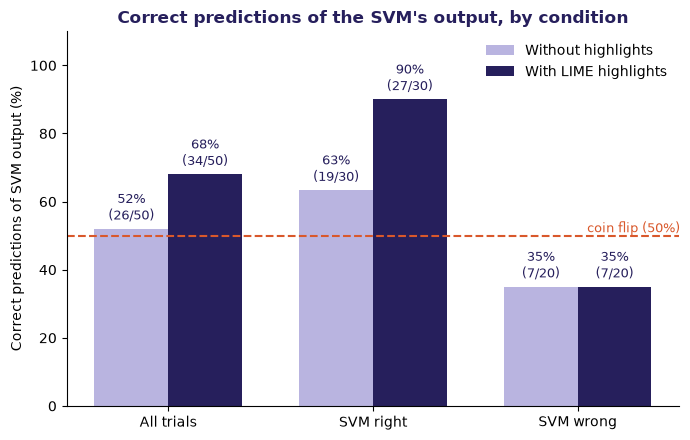

In [8]:
import matplotlib.pyplot as plt

PLAIN, HILITE, ORANGE, NAVY = "#B9B4E0", "#261F5C", "#D9582B", "#261F5C"

labels = ["All trials", "SVM right", "SVM wrong"]
subsets = [resp, resp[~resp["model_was_wrong"]], resp[resp["model_was_wrong"]]]

def acc(df, cond):
    sub = df[df["condition"] == cond]
    return sub["correct"].mean() * 100, int(sub["correct"].sum()), len(sub)

plain = [acc(d, "without highlights") for d in subsets]
high = [acc(d, "with highlights") for d in subsets]

x = np.arange(len(labels))
w = 0.36

fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x - w/2, [p[0] for p in plain], w, color=PLAIN, label="Without highlights")
b2 = ax.bar(x + w/2, [h[0] for h in high], w, color=HILITE, label="With LIME highlights")

for bars, vals in [(b1, plain), (b2, high)]:
    for bar, (pct, k, n) in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                f"{pct:.0f}%\n({k}/{n})", ha="center", va="bottom", fontsize=9, color=NAVY)

ax.axhline(50, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(len(labels) - 0.5, 51, "coin flip (50%)", color=ORANGE, ha="right", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 110)
ax.set_ylabel("Correct predictions of SVM output (%)")
ax.set_title("Correct predictions of the SVM's output, by condition", color=NAVY, fontweight="bold")
ax.legend(frameon=False, loc="upper right")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

plt.tight_layout()
plt.savefig(f"{STUDY_DIR}/figure_forward_simulation.png", dpi=200)
plt.show()

Participants predicted the SVM's output correctly in 68% of trials with highlights (34/50) and 52% without (26/50). The highlights only helped when the SVM was right: people guessed its output correctly 90% of the time (27/30) with highlights, but only 63% (19/30) without. When the SVM was wrong, highlights did not help at all. People got it right only 35% of the time (7/20) in both conditions, which is worse than a coin flip. Mean confidence was nearly identical (3.72 with highlights, 3.76 without, on a 1 to 5 scale).

With ten participants we report counts only and make no significance claims, and trials are not independent, since every participant saw every article. The errors are the cases an auditor most needs to catch, and highlights did not help there. The 35% accuracy on errors (7/20) is below chance and is consistent with participants predicting the article's true label rather than the model's output. We did not test LR in this study. Still, the result supports our recommendation: the SVM is slightly more accurate, but its explanations help people anticipate it only when it is right, not when it is wrong.